# The Servo Is a Motor, Not a Gain

The XL330 model from register value to torque, standing at two gains, and the walk inside the torque-speed limits.

[Setup and files](README.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from common import *  # noqa: F403  FMU and MuJoCo helpers, plot style

%matplotlib inline

## Stiffness and damping of the servo

In [2]:
def error_gain(register):
    return register * (4096 / (2 * np.pi)) / (256 * 885)

for register in (200, 800):
    print(f"gain {register}: saturates beyond {np.degrees(1 / error_gain(register)):.0f} deg, "
          f"stiffness {error_gain(register) * 7.4 * KT / RESISTANCE:.3f} N.m/rad at 7.4 V")
print(f"back-EMF damping {KT ** 2 / RESISTANCE:.4f} N.m.s/rad, viscous {FRICTION_VISCOUS:.4f} N.m.s/rad")

gain 200: saturates beyond 100 deg, stiffness 0.589 N.m/rad at 7.4 V
gain 800: saturates beyond 25 deg, stiffness 2.356 N.m/rad at 7.4 V
back-EMF damping 0.0478 N.m.s/rad, viscous 0.0058 N.m.s/rad


## Stand at gain 800 and 200

The exact contact with its acceleration term is stiff. Gain 800 takes about 35 s; gain 200 is stopped at 1.2 s, after the fall.

gain 800: stands at 116.2 mm
gain 200: final height -121.0 mm, below 100 mm at 0.90 s


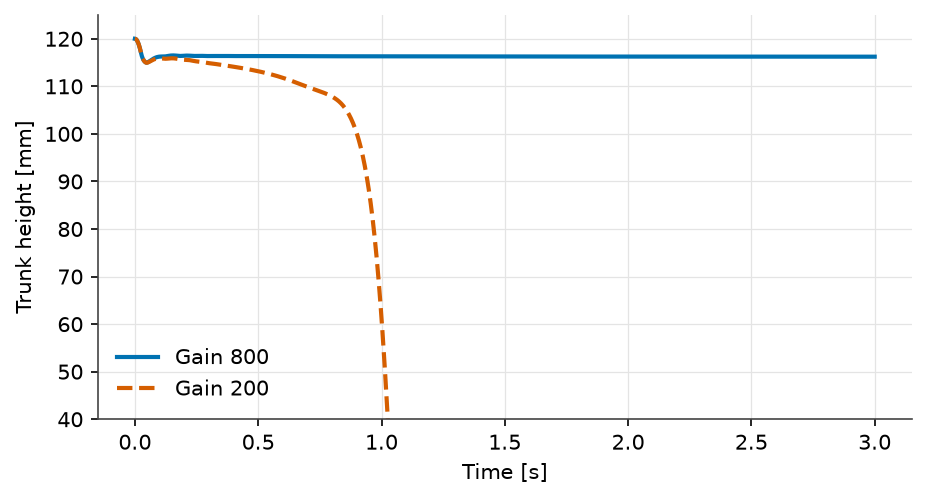

In [3]:
stiff = stand_fmu(800)
soft = stand_fmu(200, stop_time=1.2)
for name, df in (("800", stiff), ("200", soft)):
    below = df["time"][df["trunkHeight"] < 0.1]
    print(f"gain {name}: final height {1e3 * df['trunkHeight'].iloc[-1]:.1f} mm, "
          f"below 100 mm at {below.iloc[0]:.2f} s" if len(below) else f"gain {name}: stands at {1e3 * df['trunkHeight'].iloc[-1]:.1f} mm")
plt.figure(figsize=(7, 3.5))
plt.plot(stiff["time"], 1e3 * stiff["trunkHeight"], color=BLUE, label="Gain 800")
plt.plot(soft["time"], 1e3 * soft["trunkHeight"], color=ORANGE, ls="--", label="Gain 200")
plt.ylim(40, 125); plt.xlabel("Time [s]"); plt.ylabel("Trunk height [mm]"); plt.legend(); plt.show()

## The walk inside the motor limits

In [4]:
walk = walk_fmu()
late = (walk["time"] >= 2).to_numpy()
q, q_ref, tau = cols(walk, "q"), cols(walk, "qRef"), cols(walk, "servoTorque")
w = np.gradient(q, walk["time"], axis=0)
error = np.degrees(q_ref - q)[late]
for j in (3, 12):
    print(f"{JOINTS[j]}: tracking error RMS {np.sqrt((error[:, j] ** 2).mean()):.1f} deg, mean {error[:, j].mean():.1f} deg")
print(f"peak torque {np.abs(tau[late]).max():.3f} N.m, peak speed {np.abs(w[late]).max():.2f} rad/s")

left knee: tracking error RMS 24.3 deg, mean -5.9 deg
right knee: tracking error RMS 23.8 deg, mean 7.9 deg
peak torque 0.279 N.m, peak speed 6.26 rad/s


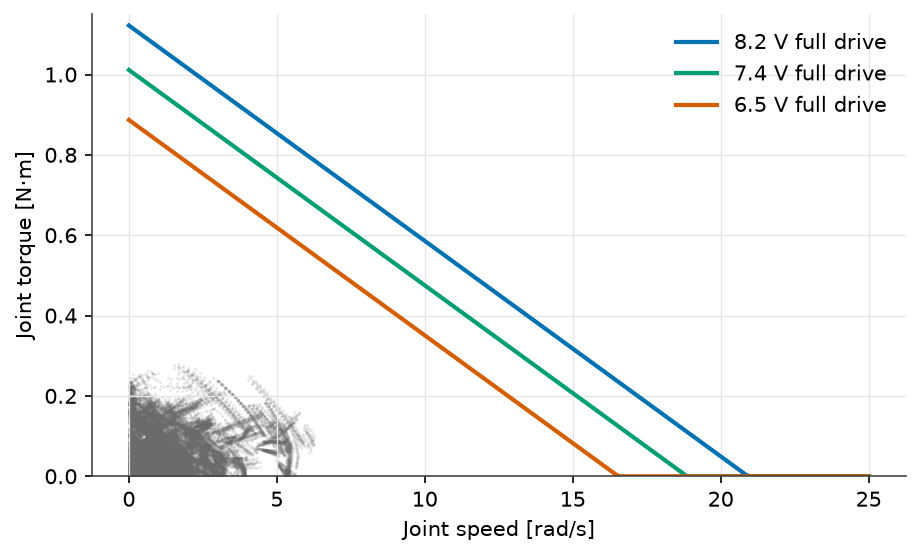

In [5]:
ws = np.linspace(0, 25, 200)
plt.figure(figsize=(7, 4))
plt.scatter(np.abs(w[late]).ravel(), np.abs(tau[late]).ravel(), s=2, color=GREY, alpha=0.15, lw=0)
for v, c in [(8.2, BLUE), (7.4, GREEN), (6.5, ORANGE)]:
    limit = KT * (v - KT * ws) / RESISTANCE - FRICTION_BASE - FRICTION_VISCOUS * ws
    plt.plot(ws, np.clip(limit, 0, None), color=c, label=f"{v} V full drive")
plt.xlabel("Joint speed [rad/s]"); plt.ylabel("Joint torque [N·m]"); plt.ylim(0, 1.15); plt.legend(); plt.show()